# TRỰC QUAN HÓA VÀ TIỀN XỬ LÝ DỮ LIỆU
File này thực hiện các bước tiền xử lý dữ liệu và trực quan hóa cho dataset YOLO (Nguyên liệu) và dataset Cookpad (Món ăn).

In [1]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Phân tích Dữ liệu YOLO (Nguyên liệu)
Đếm số lượng ảnh trong các tập train, valid, test và vẽ biểu đồ cột.

Số lượng ảnh trong mỗi tập:
- train: 11705 ảnh
- valid: 780 ảnh
- test: 522 ảnh


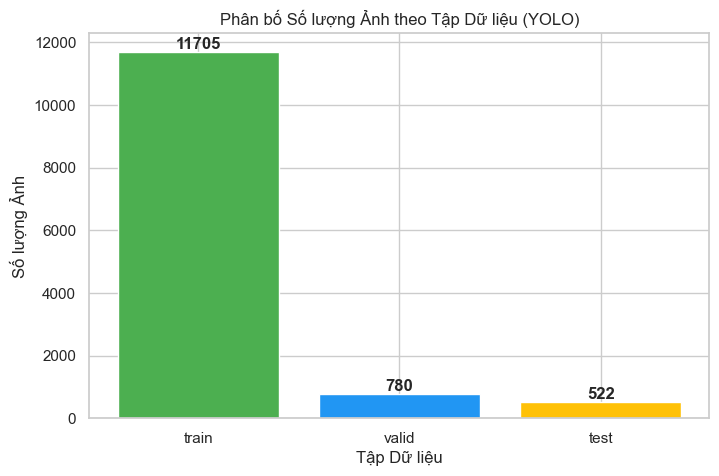

In [2]:
yolo_dir = 'Food Ingredient Recognition.v4i.yolov11'
splits = ['train', 'valid', 'test']
image_counts = {}

for split in splits:
    img_dir = os.path.join(yolo_dir, split, 'images')
    if os.path.exists(img_dir):
        image_counts[split] = len([f for f in os.listdir(img_dir) if f.endswith('.jpg') or f.endswith('.png')])
    else:
        image_counts[split] = 0

print("Số lượng ảnh trong mỗi tập:")
for k, v in image_counts.items():
    print(f"- {k}: {v} ảnh")

# Vẽ biểu đồ cột
plt.figure(figsize=(8, 5))
bars = plt.bar(image_counts.keys(), image_counts.values(), color=['#4CAF50', '#2196F3', '#FFC107'])
plt.title('Phân bố Số lượng Ảnh theo Tập Dữ liệu (YOLO)')
plt.xlabel('Tập Dữ liệu')
plt.ylabel('Số lượng Ảnh')

# Thêm số liệu trên đỉnh cột
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 10, int(yval), ha='center', va='bottom', fontweight='bold')

plt.show()

## 2. Tiền xử lý Dữ liệu Cookpad (Món ăn)
Lọc bỏ các món ăn có chứa từ 'combo' hoặc dấu '+' trong tên. 
Vẽ biểu đồ cột so sánh số lượng và Boxplot thời gian nấu trước/sau khi lọc.

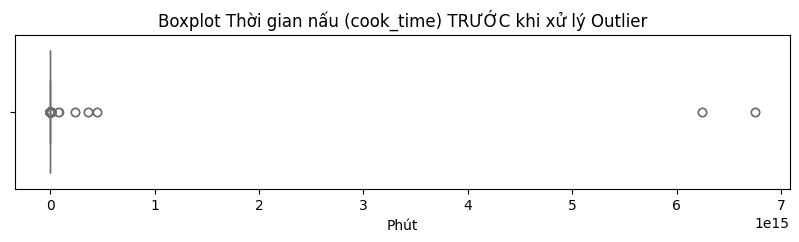

In [1]:
# Cần import lại thư viện nếu chạy ở phiên mới
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df_clean = pd.read_json('cookpad_dataset1.json')
# Vẽ Boxplot TRƯỚC khi xử lý
plt.figure(figsize=(10, 2))
sns.boxplot(x=df_clean['cook_time'], color='salmon')
plt.title('Boxplot Thời gian nấu (cook_time) TRƯỚC khi xử lý Outlier')
plt.xlabel('Phút')
plt.show()

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Tách dữ liệu thành nhóm Hợp lệ và nhóm Outlier (rác/lỗi)
valid_mask = (df_clean['cook_time'] > 0) & (df_clean['cook_time'] <= 500)
outlier_mask = ~valid_mask

df_valid = df_clean[valid_mask].copy()
df_outlier = df_clean[outlier_mask].copy()

print(f"📊 Số lượng món ăn thời gian hợp lệ: {len(df_valid)}")
print(f"⚠️ Số lượng món ăn bị lỗi thời gian (Outlier): {len(df_outlier)}")

# 1. Tạo hàm gộp chuỗi đặc trưng cho mỗi món ăn (Tên + Nguyên liệu)
def get_recipe_text(row):
    ingredients_str = " ".join(row.get('ingredients', []))
    return str(row.get('title', '')) + " " + ingredients_str

valid_texts = df_valid.apply(get_recipe_text, axis=1)
outlier_texts = df_outlier.apply(get_recipe_text, axis=1)

# 2. Mã hóa văn bản thành Vector bằng TF-IDF
vectorizer = TfidfVectorizer()
valid_tfidf = vectorizer.fit_transform(valid_texts)
outlier_tfidf = vectorizer.transform(outlier_texts)

# 3. Tính độ tương đồng (Cosine Similarity) giữa Outlier và Hợp lệ
print("🔄 Đang tính toán độ tương đồng và sửa lỗi thời gian nấu...")
similarities = cosine_similarity(outlier_tfidf, valid_tfidf)

# 4. Tìm Top 5 món tương tự nhất và lấy trung vị thời gian
imputed_times = []
for i in range(len(df_outlier)):
    sim_scores = similarities[i]
    # Lấy index của 5 món có độ tương đồng cao nhất
    top_5_indices = sim_scores.argsort()[-5:][::-1]
    
    # Lấy thời gian nấu của 5 món này
    similar_cook_times = df_valid.iloc[top_5_indices]['cook_time']
    
    # Tính trung vị (median) để gán lại (tránh bị ảnh hưởng nếu 1 trong 5 món hơi lệch)
    median_time = int(similar_cook_times.median())
    imputed_times.append(median_time)

# Cập nhật thời gian nấu mới cho nhóm Outlier
df_outlier['cook_time'] = imputed_times

# Gộp lại thành một DataFrame hoàn chỉnh
df_cleaned_time = pd.concat([df_valid, df_outlier]).reset_index(drop=True)

print("✅ Đã hoàn tất gán lại thời gian nấu dựa trên các món ăn tương tự!")


📊 Số lượng món ăn thời gian hợp lệ: 6840
⚠️ Số lượng món ăn bị lỗi thời gian (Outlier): 8840
🔄 Đang tính toán độ tương đồng và sửa lỗi thời gian nấu...
✅ Đã hoàn tất gán lại thời gian nấu dựa trên các món ăn tương tự!


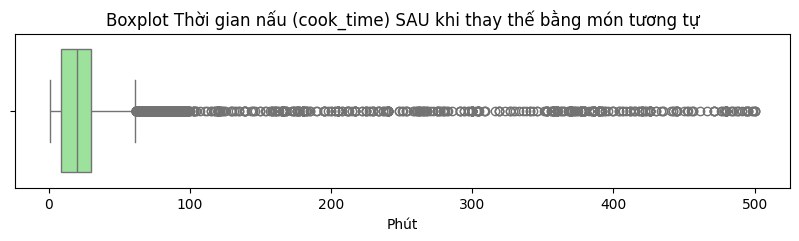

count    15680.000000
mean        31.203253
std         55.295471
min          1.000000
25%          9.000000
50%         20.000000
75%         30.000000
max        500.000000
Name: cook_time, dtype: float64


In [7]:
# Vẽ Boxplot kiểm tra lại
plt.figure(figsize=(10, 2))
sns.boxplot(x=df_cleaned_time['cook_time'], color='lightgreen')
plt.title('Boxplot Thời gian nấu (cook_time) SAU khi thay thế bằng món tương tự')
plt.xlabel('Phút')
plt.show()

# Xem thống kê chung
print(df_cleaned_time['cook_time'].describe())

## 3. Đánh giá Tỉ lệ Ghép nối (Matching Threshold)
Kiểm tra xem bao nhiêu công thức chứa ít nhất 1 nguyên liệu mà mô hình YOLO có thể nhận diện được.

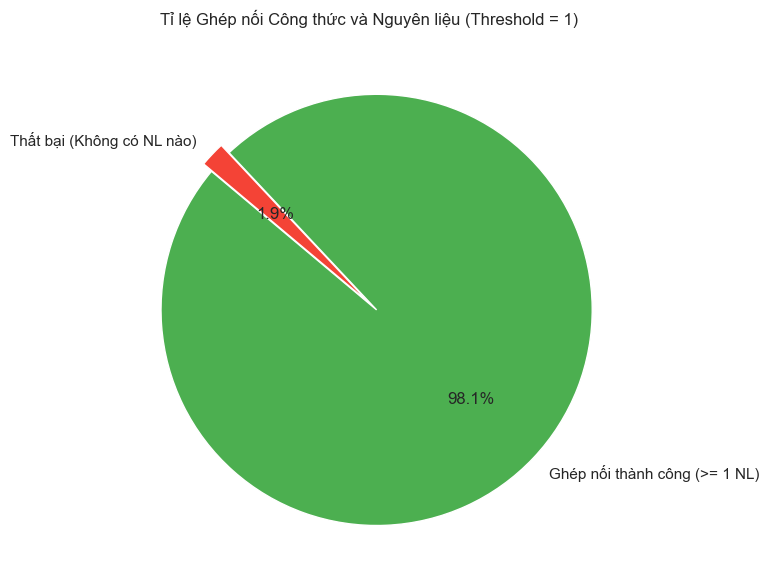

Giữ lại 15383 công thức hợp lệ để dùng cho AI.


In [9]:
# Danh sách 61 class từ data.yaml
class_names = [
    'táo', 'măng tây', 'bơ', 'chuối', 'ớt chuông', 'mướp đắng', 'cải chíp', 'bông cải xanh', 
    'bắp cải', 'cà rốt', 'hạt điều', 'bông cải trắng', 'su su', 'ức gà', 'đùi gà', 'cánh gà', 
    'ớt', 'dừa', 'ngô', 'cua', 'dưa chuột', 'trứng', 'cà tím', 'tỏi', 'gừng', 'nho', 'chanh', 
    'xà lách', 'đuôi tôm hùm', 'xoài', 'dưa lưới', 'sữa', 'hành tây', 'cam', 'hàu', 'đu đủ', 
    'đậu phộng', 'đậu Hà Lan', 'hạt tiêu', 'tiêu', 'dứa', 'thịt ba chỉ', 'khoai tây', 'bí đỏ', 
    'củ cải', 'gạo lứt đỏ', 'cá hồi', 'sò điệp', 'tôm', 'cải bó xôi', 'dâu tây', 'khoai lang', 
    'tempeh', 'đậu hũ', 'cà chua', 'cá ngừ', 'gạo trắng', 'hành', 'gà', 'cá', 'thịt'
]

def count_matched_ingredients(ingredients_list):
    count = 0
    joined_ingredients = " ".join(ingredients_list).lower()
    for cls in class_names:
        if cls in joined_ingredients:
            count += 1
    return count

# Tính số lượng nguyên liệu match cho mỗi công thức
df_cleaned_time['matched_yolo_count'] = df_cleaned_time['ingredients'].apply(count_matched_ingredients)

# Đặt Threshold: Cần ít nhất 1 nguyên liệu match
threshold = 1
df_cleaned_time['is_matchable'] = df_cleaned_time['matched_yolo_count'] >= threshold

match_counts = df_cleaned_time['is_matchable'].value_counts()
labels = ['Ghép nối thành công (>= 1 NL)', 'Thất bại (Không có NL nào)']

# Cẩn thận nếu tất cả đều match hoặc không match
sizes = []
for boolean_val in [True, False]:
    sizes.append(match_counts.get(boolean_val, 0))

plt.figure(figsize=(7, 7))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, colors=['#4CAF50', '#F44336'], explode=(0.05, 0))
plt.title(f'Tỉ lệ Ghép nối Công thức và Nguyên liệu (Threshold = {threshold})')
plt.show()

# Lọc và lưu data mới
df_final = df_cleaned_time[df_cleaned_time['is_matchable'] == True]
print(f"Giữ lại {len(df_final)} công thức hợp lệ để dùng cho AI.")


In [10]:
# Ghi nhận kết quả ra file JSON mới để AI (yolo_recipe_xai.py) sử dụng
cleaned_file_path = 'cookpad_dataset_cleaned.json'
df_final = df_final.drop(columns=['matched_yolo_count', 'is_matchable'], errors='ignore')
df_final.to_json(cleaned_file_path, orient='records', force_ascii=False)

print(f"💾 Đã lưu tập dữ liệu sạch vào: {cleaned_file_path}")

💾 Đã lưu tập dữ liệu sạch vào: cookpad_dataset_cleaned.json
